# `pyGIMLi(emg3d)`

Requires
- `pygimli>=1.5.2`
- `emg3d@inv-pygimli` (`pip install git+https://github.com/emsig/emg3d@inv-pygimli`

Super simple plus all possible inv-crimes (same mesh, some solver, ...).

In [60]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

import emg3d
import ipygimli as ipygimli
from Emg3d_extra_grid_functions import *


## Create synthetic data

To run the example code we need a simulation class and a subsurface model

I here reproduce the model I used in previous forward-modeling (v1), with a cuboid hot plume inside

### Define survey and baseline resistivity model

In [2]:
# Source
source = [0, -126, 0, 90.0, 0] # y-directed point dipole on the surface

src = emg3d.surveys.txrx_coordinates_to_dict(
        emg3d.TxElectricDipole,
        (0, -126, 0, 90.0, 0.0)
)

# Source frequency
frequency = 1

# Receiver offsets
offsets = np.arange(0, 300, 7.5)  # 300 m long receiver line

# receiver-array: x, y, z, azimuth, dip
receivers = (offsets*0, [74]*len(offsets), -offsets, 0, 90)  # z-directed, Ez response

# Receiver positions, vertical z-directed point dipoles
rec_x = np.arange(1, 41)*0
rec_y = np.array([74]*40)
rec_z = np.arange(1,41)*-7.5
rec = emg3d.surveys.txrx_coordinates_to_dict(
        emg3d.RxElectricPoint,
        (rec_x, rec_y, rec_z, 0.0, 90.0)
)

# Layer boundaries
# We idealize the depth model here a bit, to have cells of 10m in depth
depth = [0, -50, -80, -120, -190]

# Layer resistivities in Ohm.m for the baseline
resistivities_base = np.array([1e8, 52.0, 38.0, 26.0, 29.5, 17.5]) # base incl. air (lower res, because of 3D modelling)

In [3]:
# define the input that stays the same for all models
inp = {
    'src': source,
    'rec': receivers,
    'depth': depth,
    'freqtime': frequency,
    'srcpts': 5,  # Models the finite-length source as 5 point sources with Gaussian Quadrature
    'htarg': {'pts_per_dec': -1},  # Faster computation
    'verb': 1,
    'strength': 1,
}

In [4]:
grid = emg3d.construct_mesh(
    center=(0,0,0),                                 # Center of wanted grid
    frequency=frequency,                            # Frequency we will use the grid for
    properties=[25, 1e8],                           # Reference resistivity
    domain=([-150, 150], [-300, 300], [-250, 0]),   # Domain in which we want precise results
    center_on_edge=True,
    min_width_limits = [10, 10, 5],
)
 
grid  # mesh info
#grid.plot_grid() # plotting the grid

TensorMesh: 983,040 cells

                      MESH EXTENT             CELL WIDTH      FACTOR
  dir    nC        min           max         min       max      max
  ---   ---  ---------------------------  ------------------  ------
   x     80   -103,135.26    103,135.26     10.00 28,028.05    1.37
   y    128   -105,016.88    105,016.88     10.00 21,122.27    1.25
   z     96   -105,145.43    156,825.85      5.00 51,925.42    1.49

In [5]:
#Insert resistivity values into the grid

# Pre-allocate an array with number of cells corresponding to our grid
res_base = np.ones(grid.shape_cells)

# Layered base model: Fill in layered resistivities into our grid and create model
dd = np.r_[np.inf, depth, -np.inf]
for i in range(len(resistivities_base)):
    res_base[:, :, (grid.cell_centers_z > dd[i+1]) & (grid.cell_centers_z <= dd[i])] = resistivities_base[i]

model_base = emg3d.Model(grid, property_x=res_base, mapping='Resistivity')

In [6]:
model_base_conductivity = emg3d.Model(grid, property_x=1/np.array(res_base), mapping='Conductivity')

### Create target model (COMSOL plume)


In [32]:
#load existing custom plume resistivities

res_target3 = np.loadtxt('test_plume_1_interpolated.txt')
print(np.shape(res_base))

model_target3 = emg3d.Model(grid, property_x=res_target3, mapping='Resistivity')

(80, 128, 96)


In [33]:
model_target3_conductivity = emg3d.Model(grid, property_x=1/np.array(res_target3), mapping='Conductivity')

In [34]:
rec_coords = receivers
src_coords = source

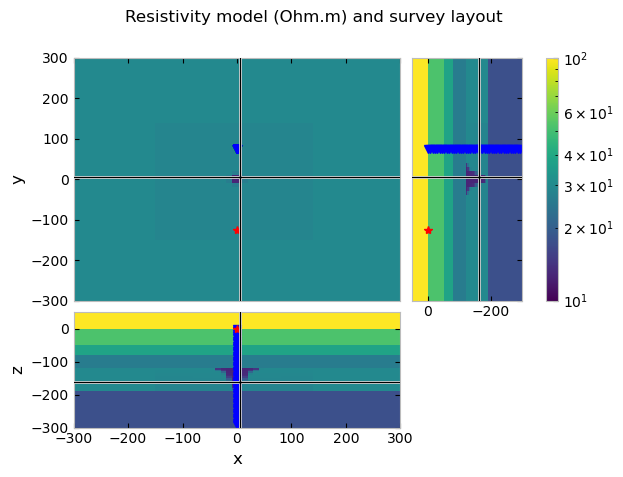

In [35]:
#QC cube location
grid.plot_3d_slicer(
    model_target3.property_x,
    pcolor_opts={'norm': LogNorm(vmin=10, vmax=100)},
    xlim=[-300, 300],
    ylim=[-300, 300],
    zlim=[-300, 50],
    zslice=-160,
)
# Plot survey in figure above
fig = plt.gcf()
fig.suptitle('Resistivity model (Ohm.m) and survey layout')
axs = fig.get_children()
rec_coords = receivers
src_coords = source
axs[1].plot(rec_coords[0], rec_coords[1], 'bv')
axs[2].plot(rec_coords[0], rec_coords[2], 'bv')
axs[3].plot(rec_coords[2], rec_coords[1], 'bv')
axs[1].plot(src_coords[0], src_coords[1], 'r*')
axs[2].plot(src_coords[0], src_coords[2], 'r*')
axs[3].plot(src_coords[2], src_coords[1], 'r*')
axs[1].grid(False)
axs[2].grid(False)
axs[3].grid(False)

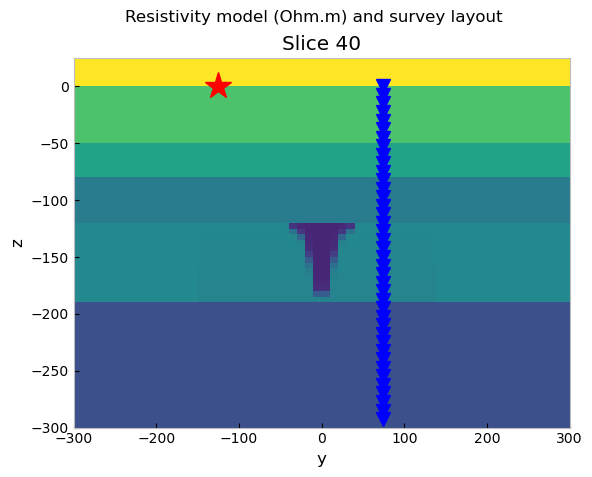

In [36]:
#Focus on the y,z plane
grid.plot_slice(
    model_target3.property_x,
    normal = 'X',
    pcolor_opts={'norm': LogNorm(vmin=10, vmax=100)},
    range_x=[-300, 300],
    range_y=[-300, 25],
#    slice_loc=0
)
fig = plt.gcf()
fig.suptitle('Resistivity model (Ohm.m) and survey layout')
axs = fig.get_children()
axs[1].plot(rec_coords[1], rec_coords[2], 'bv', markersize = 10)
axs[1].plot(src_coords[1], src_coords[2], 'r*', markersize = 20)
axs[1].grid(False)

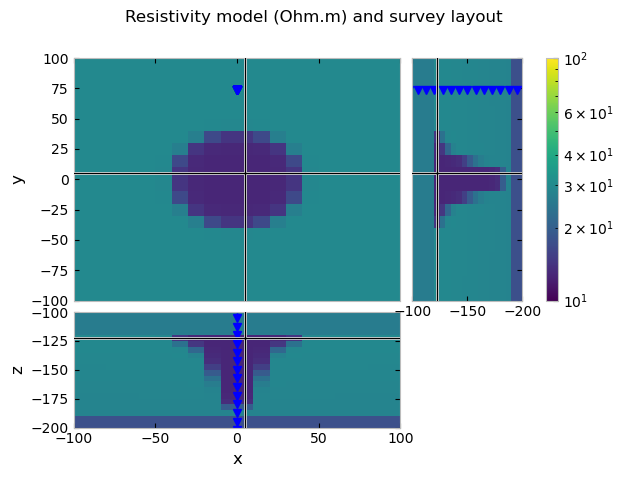

In [52]:
#QC cube location
grid.plot_3d_slicer(
    model_target3.property_x,
    pcolor_opts={'norm': LogNorm(vmin=10, vmax=100)},
    xlim=[-100, 100],
    ylim=[-100, 100],
    zlim=[-200, -100],
    zslice=-120,
)
# Plot survey in figure above
fig = plt.gcf()
fig.suptitle('Resistivity model (Ohm.m) and survey layout')
axs = fig.get_children()
rec_coords = receivers
src_coords = source
axs[1].plot(rec_coords[0], rec_coords[1], 'bv')
axs[2].plot(rec_coords[0], rec_coords[2], 'bv')
axs[3].plot(rec_coords[2], rec_coords[1], 'bv')
axs[1].plot(src_coords[0], src_coords[1], 'r*')
axs[2].plot(src_coords[0], src_coords[2], 'r*')
axs[3].plot(src_coords[2], src_coords[1], 'r*')
axs[1].grid(False)
axs[2].grid(False)
axs[3].grid(False)

### Create the simulated data

This code is based on sensitivity gradient notebook v1_7

In [37]:
#Generate frequency- and source-dependent grids
gopts = {
    'properties': [25, 1e8],
    'min_width_limits': [10, 10, 5],
    #'stretching': (None, None, [1.0, 1.5]),
    'domain': (
        [-150, 150],
        [-300, 300],
        [-300, 0]
    ),
    'center_on_edge': False,
}

In [38]:
survey = emg3d.surveys.Survey(
    name='Survey cuboid target model',  # Name of the survey
    sources=src,               # Source coordinates
    receivers=rec,             # Receiver coordinates
    frequencies=frequency,   # Two frequencies
    # data=data,               # Adding the observed data here will allow sensitivity calculation later, but we need to generate it first
    noise_floor=1e-15,
    relative_error=0.10,
)

survey

:: Survey «Survey cuboid target model» ::

<xarray.Dataset> Size: 2kB
Dimensions:   (src: 1, rec: 40, freq: 1)
Coordinates:
  * src       (src) <U6 24B 'TxED-1'
  * rec       (rec) <U7 1kB 'RxEP-01' 'RxEP-02' ... 'RxEP-39' 'RxEP-40'
  * freq      (freq) <U3 12B 'f-1'
Data variables:
    observed  (src, rec, freq) complex128 640B (nan+nanj) ... (nan+nanj)
Attributes:
    noise_floor:     1e-15
    relative_error:  0.1

In [39]:
simulation = emg3d.simulations.Simulation(
            name='Simulation of cuboid target model',    # A name for this simulation
            survey=survey,        # Our survey instance
            model=model_base_conductivity,          # The model
            gridding='both',      # Frequency- and source-dependent meshes
            max_workers=4,        # How many parallel jobs
            # solver_opts,        # Any parameter to pass to emg3d.solve
            gridding_opts=gopts,  # Gridding options
            receiver_interpolation = "linear" #Needed for correct computation of the gradient
        )

simulation.compute(observed=True)

Compute efields            0/1  [00:00]

## Load Simulation (incl. Survey, Models, Data)

In [40]:
sim = simulation
model_res = model_target3
model = model_target3_conductivity
model_init = sim.model.copy()

# sim.tol_gradient = 1e-2  # could be reduced further to potentially speed-up more

## Define regions, instantiate Kernel and Inversion

In [41]:
print(sim.model.shape)
print(model.property_x.shape)

(80, 128, 96)
(80, 128, 96)


In [42]:
print(np.shape(grid.cell_centers_z))

(96,)


In [43]:
# Create region markers
markers = np.zeros(sim.model.shape, dtype=int)
print(np.sum(markers))
print(80*128*96)
#markers[grid.cell_centers_x < 150 and grid.cell_centers_y < 150 and ] = 1
markers = change_cuboid_resistivity(markers, grid, 50, 50, -190, -120, 1)            # Only target is free
#markers[grid.cell_centers_x < 150,grid.cell_centers_y > 150,3] = 1
#markers[grid.cell_centers_x < 150, grid.cell_centers_y > 150, grid.cell_centers_z < -100] = 1          # Only target is free
print(np.sum(markers))

0
983040
[-50, -50, -190] [50, 50, -120]
x bounds:  -45.00000000001759  ,  44.99999999998241
y_bounds:  -44.99999999999443  ,  45.00000000000557
z_bounds:  -187.49999999999577  ,  -117.49999999999577
1134


In [44]:
# Create region markers
#markers = np.zeros(sim.model.shape, dtype=int)
#markers[grid.cell_centers_x < 150 & grid.cell_centers_y < 150 & grid.cell_centers_z < -100 & grid.cell_centers_z > -200] = 1            # Only target is free

# Instantiate the emg3d-kernel for pyGIMLi
fop = ipygimli.Kernel(simulation=sim, markers=markers, pgthreads=1)

# Instantiate the inversion and set some inversion parameters
INV = ipygimli.Inversion(fop=fop)
#INV.inv.setCGLSTolerance(1)  # is _absolute_, not _relative_
INV.inv.setMaxCGLSIter(10)

# Set the regions.
INV.fop.setRegionProperties(1, limits=(0.0001, 2), startModel=1)                  # Target
INV.fop.setRegionProperties(0, background=True)                                   # Background

## Run inversion

In [45]:
INV.run(
    #maxIter=2, # just to test
    lam=100,  # btw 1-100
    lambdaFactor=0.9,
    stopAtChi1=False,
    #dPhi=5.0,
    #verbose=True,
    #debug=True,
    #startModel=model.property_x.ravel('F'),
    #isReference=True,
)

13/08/26 - 15:21:02 - pyGIMLi - INFO - :: pyGIMLi(emg3d) START ::


Compute efields            0/1  [00:00]

13/08/26 - 15:22:08 - pyGIMLi - INFO - ===========================================================================
                                        it   F(m)         χ²          λ         ϕᵈ         ϕᵐ   ϕ=ϕᵈ+λϕᵐ   Δϕ (%)
                                       ---------------------------------------------------------------------------
13/08/26 - 15:22:08 - pyGIMLi - INFO -   0      1        6.1      100.0      490.1        0.0      490.1     0.00


Compute jvec            0/1  [00:00]

Back-propagate            0/1  [00:00]

Back-propagate            0/1  [00:00]

... (71 outputs left out)

Back-propagate            0/1  [00:00]

Compute efields            0/1  [00:00]

Compute efields            0/1  [00:00]

13/08/26 - 15:42:24 - pyGIMLi - INFO -   3     25        6.1       81.0      488.4        0.0      489.4     0.02
13/08/26 - 15:42:24 - pyGIMLi - INFO - :: pyGIMLi(emg3d) END   :: runtime = 0:21:22


# Plots

In [57]:
import sampledata

Depth slice: -58794.46 m


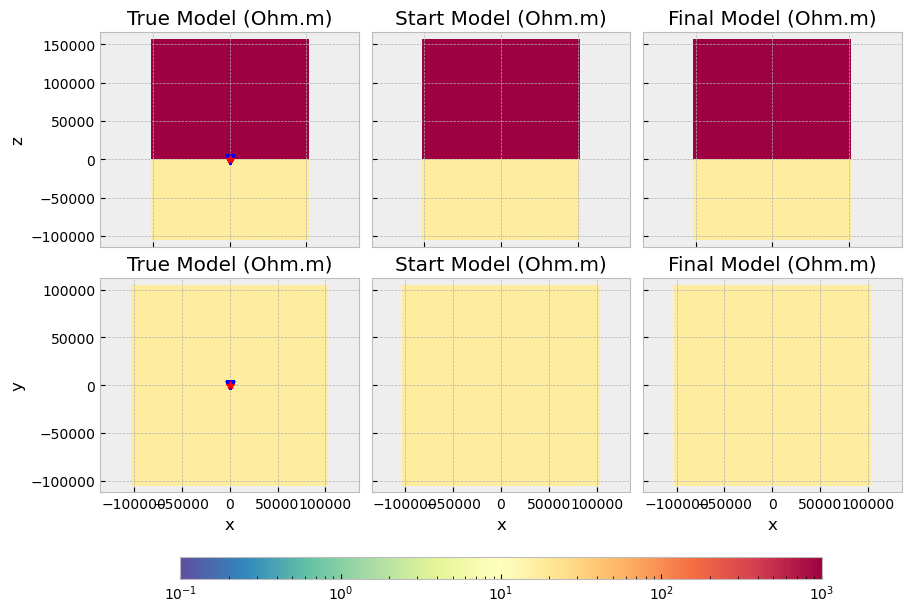

In [59]:
sampledata.plot_models(sim, model_init, model)

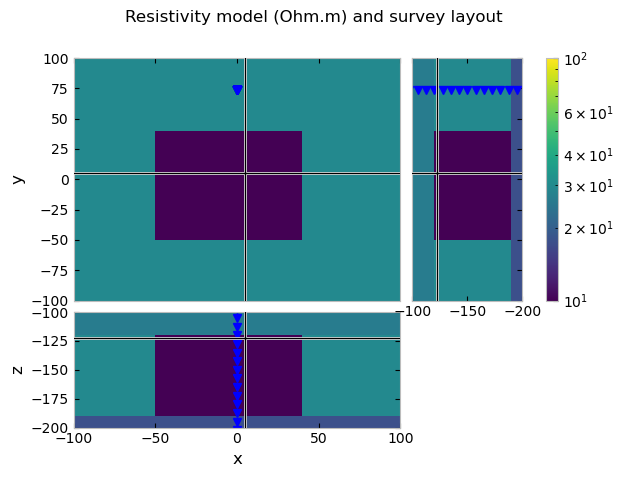

In [56]:
#QC cube location
grid.plot_3d_slicer(
    1/fop.model2emg3d(INV.modelHistory[-1]),
    pcolor_opts={'norm': LogNorm(vmin=10, vmax=100)},
    xlim=[-100, 100],
    ylim=[-100, 100],
    zlim=[-200, -100],
    zslice=-120,
)
# Plot survey in figure above
fig = plt.gcf()
fig.suptitle('Resistivity model (Ohm.m) and survey layout')
axs = fig.get_children()
rec_coords = receivers
src_coords = source
axs[1].plot(rec_coords[0], rec_coords[1], 'bv')
axs[2].plot(rec_coords[0], rec_coords[2], 'bv')
axs[3].plot(rec_coords[2], rec_coords[1], 'bv')
axs[1].plot(src_coords[0], src_coords[1], 'r*')
axs[2].plot(src_coords[0], src_coords[2], 'r*')
axs[3].plot(src_coords[2], src_coords[1], 'r*')
axs[1].grid(False)
axs[2].grid(False)
axs[3].grid(False)

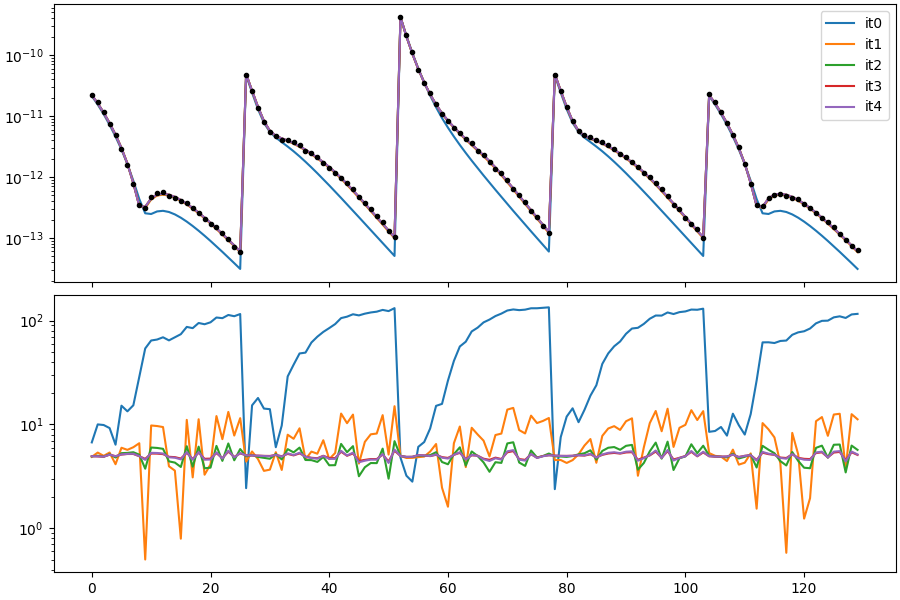

In [7]:
plot_responses(sim)

In [8]:
emg3d.Report()

--------------------------------------------------------------------------------
  Date: Tue Sep 10 17:08:40 2024 CEST

                OS : Linux (Ubuntu 22.04)
            CPU(s) : 16
           Machine : x86_64
      Architecture : 64bit
               RAM : 31.0 GiB
       Environment : Jupyter
       File system : ext4

  Python 3.11.9 | packaged by conda-forge | (main, Apr 19 2024, 18:36:13) [GCC
  12.3.0]

             numpy : 1.26.4
             scipy : 1.14.0
             numba : 0.59.1
             emg3d : 1.8.4.dev6+gd2f88de
           empymod : 2.3.1
            xarray : 2024.6.0
        discretize : 0.10.0
              h5py : 3.11.0
        matplotlib : 3.9.1
              tqdm : 4.66.4
           IPython : 8.26.0
           pygimli : 1.5.2
            pgcore : 1.5.0
--------------------------------------------------------------------------------